Running sample-average method...
Running constant step-size method...


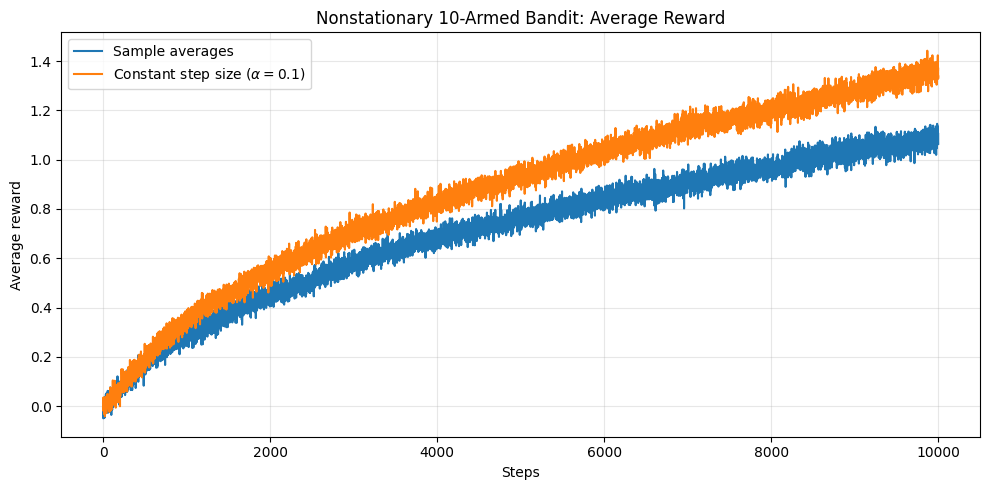

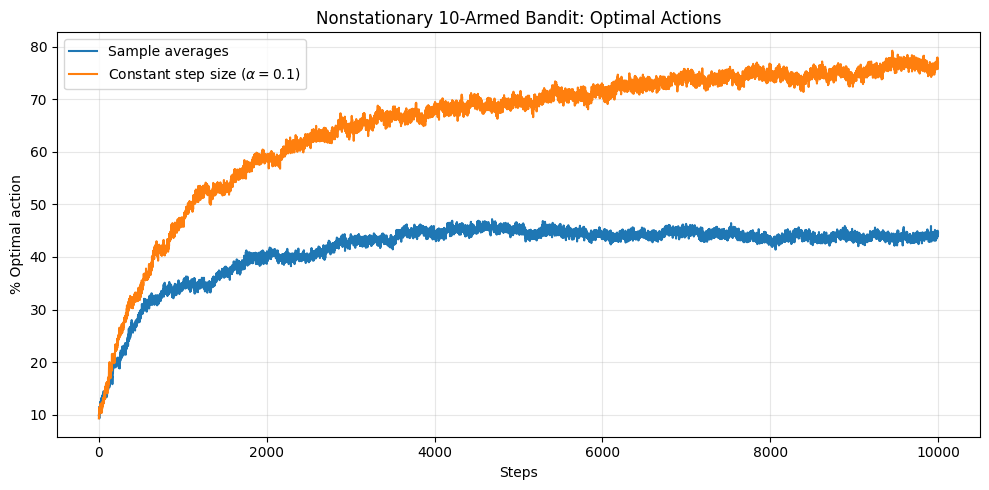

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
NUM_RUNS = 2000
NUM_STEPS = 10000
NUM_ARMS = 10
EPSILON = 0.1
ALPHA = 0.1

rng = np.random.default_rng(42)


def simulate(method):
    rewards = np.zeros((NUM_RUNS, NUM_STEPS))
    optimal_actions = np.zeros((NUM_RUNS, NUM_STEPS))

    for run in range(NUM_RUNS):

        # All true action values start equal
        q_true = np.zeros(NUM_ARMS)

        # Estimated action values and action counts
        q_est = np.zeros(NUM_ARMS)
        counts = np.zeros(NUM_ARMS)

        for step in range(NUM_STEPS):

            # Epsilon-greedy action selection
            if rng.random() < EPSILON:
                action = rng.integers(NUM_ARMS)
            else:
                greedy_actions = np.flatnonzero(
                    q_est == np.max(q_est)
                )
                action = rng.choice(greedy_actions)

            # Identify the currently optimal action
            best_action = np.argmax(q_true)
            optimal_actions[run, step] = (
                action == best_action
            )

            # Generate reward from the current action value
            reward = q_true[action] + rng.standard_normal()
            rewards[run, step] = reward

            # Update action-value estimate
            counts[action] += 1

            if method == "sample_average":
                q_est[action] += (
                    reward - q_est[action]
                ) / counts[action]

            elif method == "constant_step":
                q_est[action] += ALPHA * (
                    reward - q_est[action]
                )

            # Independent random walk for all true values
            q_true += rng.normal(
                0.0, 0.01, size=NUM_ARMS
            )

    avg_reward = rewards.mean(axis=0)
    optimal_percentage = optimal_actions.mean(axis=0) * 100

    return avg_reward, optimal_percentage


# Run both methods
print("Running sample-average method...")
r_sample, opt_sample = simulate("sample_average")

print("Running constant step-size method...")
r_constant, opt_constant = simulate("constant_step")


# Plot 1: Average reward
plt.figure(figsize=(10, 5))

plt.plot(r_sample, label="Sample averages")
plt.plot(
    r_constant,
    label=r"Constant step size ($\alpha=0.1$)"
)

plt.xlabel("Steps")
plt.ylabel("Average reward")
plt.title("Nonstationary 10-Armed Bandit: Average Reward")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# Plot 2: Percentage of optimal actions
plt.figure(figsize=(10, 5))

plt.plot(r_sample * 0 + opt_sample, label="Sample averages")
plt.plot(
    opt_constant,
    label=r"Constant step size ($\alpha=0.1$)"
)

plt.xlabel("Steps")
plt.ylabel("% Optimal action")
plt.title("Nonstationary 10-Armed Bandit: Optimal Actions")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()